# **Funzioni comuni**  
Costanti e funzioni usate dalle celle sotto (caricamento, intervalli di fase, finestre da 30 s, etichette, normalizzazione). Va eseguita per prima.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

DATA_DIR = "VitaStress/data/"
WINDOW = "30s"  # "resampled to have a sampling frequency of 1/30 seconds" (preprint, sez. 3.6)

# etichette Start/Stop per fase, osservate in *_annotation.csv (non uniformi tra loro,
# "public" usa deliberatamente solo il discorso, non la preparazione)
PHASE_LABELS = {
    "baseline": ("Baseline Start (Start of Experiment)", "Baseline Stop"),
    "cognitive": ("Cognitive: Start", "Cognitive: Stop"),
    "physical": ("Physical: Start", "Physical: Stop"),
    "public": ("Public Speaking Start", "Public Speaking Stop"),
}
PHASES = list(PHASE_LABELS.keys())  # solo i nomi delle fasi: baseline, cognitive, physical, public

# schema della pipeline (preprint, Figura 3): l'accelerometro (grezzo, ~32 Hz) viene
# AGGREGATO per finestra con mean/std/var, i segnali vitali (già processati da Corsano)
# vengono solo RICAMPIONATI sulla stessa griglia
ACC_SOURCE = ("_acc.csv", ["accX", "accY", "accZ"])
VITAL_SOURCES = {
    "_activity.csv": ["bpm"],
    "_emography.csv": ["stress_skin"],  # EDA / skin conductance
    "_temperature.csv": ["temp_sk1"],  # la "skin temperature" del paper (in realtà CBT); temp_sk2 è sempre 0
}

# colonne in cui un valore mancante è scritto come 0 invece che lasciato vuoto
ZERO_IS_MISSING = {"bpm", "temp_sk1"}


def subject_files(subject_dir):
    """Path di tutti i file del soggetto, indicizzati per suffisso esatto:
    "<uuid>_temperature.csv" -> "_temperature.csv". Gli UUID non contengono "_",
    quindi il suffisso inizia al primo "_". Con endswith() invece
    "_heat_flux_sensor_temperature.csv" verrebbe preso anche per "_temperature.csv"."""
    with os.scandir(subject_dir) as files:
        return {f.name[f.name.find("_"):]: f.path for f in files}


def get_phase_intervals(annotation_csv_path):
    """Per ciascuna fase: (ultimo Start prima dell'ultimo Stop, ultimo Stop).
    Gestisce riavvii/duplicati nelle annotation. Ritorna None per una fase
    se manca lo Start o lo Stop corrispondente."""
    ann = pd.read_csv(annotation_csv_path)
    # format="ISO8601": alcune righe non hanno i microsecondi, un formato fisso
    # inferito dalla prima riga fallisce sulle righe con precisione diversa
    ann["timestamp"] = pd.to_datetime(ann["timestamp"], utc=True, format="ISO8601")

    intervals = {}
    for phase, (start_label, stop_label) in PHASE_LABELS.items():
        stops = ann.loc[ann["Button Name"] == stop_label, "timestamp"]
        if stops.empty:
            intervals[phase] = None
            continue
        stop = stops.max()

        starts = ann.loc[(ann["Button Name"] == start_label) & (ann["timestamp"] < stop), "timestamp"]
        if starts.empty:
            intervals[phase] = None
            continue
        start = starts.max()

        intervals[phase] = (start, stop)
    return intervals


def read_signal(path, columns):
    """Colonne richieste di un CSV, indicizzate per data, con gli zeri-mancanti a NaN."""
    df = pd.read_csv(path, usecols=["date", *columns])
    df["date"] = pd.to_datetime(df["date"], utc=True, format="ISO8601")
    for col in columns:
        if col in ZERO_IS_MISSING:
            df[col] = df[col].replace(0, np.nan)
    return df.set_index("date")


def resample_vital(signal):
    """Ricampiona un segnale vitale sulla griglia da WINDOW. Se il segnale è più lento
    della finestra (emography: 1 valore/min) il ricampionamento lascia finestre vuote
    tra un valore e l'altro: riempiamo solo quei buchi per interpolazione lineare, non i
    mancanti veri (nel paper stress_skin ha ~0% di mancanti, Figura 4)."""
    resampled = signal.resample(WINDOW).mean()
    native_step = signal.index.to_series().diff().median()
    holes = int(native_step / pd.Timedelta(WINDOW)) - 1
    if holes > 0:
        resampled = resampled.interpolate(method="linear", limit=holes, limit_area="inside")
    return resampled


def subject_windows(paths):
    """Una riga per finestra da WINDOW con tutte le feature del soggetto affiancate
    (allineamento: tutte le sorgenti sono sulla stessa griglia temporale)."""
    suffix, columns = ACC_SOURCE
    acc = read_signal(paths[suffix], columns).resample(WINDOW).agg(["mean", "std", "var"])
    acc.columns = [f"{col}_{stat}" for col, stat in acc.columns]  # ("accX", "mean") -> "accX_mean"

    signals = [acc]
    for suffix, columns in VITAL_SOURCES.items():
        signals.append(resample_vital(read_signal(paths[suffix], columns)))
    return pd.concat(signals, axis=1, sort=True)


def label_windows(windows, intervals):
    """Tiene solo le finestre interamente contenute in una delle 4 fasi e aggiunge
    la colonna "phase". L'indice è l'inizio della finestra."""
    labeled = []
    for phase, interval in intervals.items():
        if interval is None:
            continue
        start, stop = interval
        inside = (windows.index >= start) & (windows.index + pd.Timedelta(WINDOW) <= stop)
        labeled.append(windows[inside].assign(phase=phase))
    return pd.concat(labeled)


def build_window_table():
    """Tabella di tutti i soggetti: una riga per finestra etichettata, colonne
    feature + "phase" + "subject" (NON normalizzata). Ritorna anche la lista
    (soggetto, motivo) di cosa è stato scartato."""
    tables = []
    skipped = []

    with os.scandir(DATA_DIR) as entries:
        subject_dirs = sorted((e for e in entries if e.is_dir()), key=lambda e: e.name)

    for subject_dir in subject_dirs:
        paths = subject_files(subject_dir)

        missing = [s for s in ["_annotation.csv", ACC_SOURCE[0], *VITAL_SOURCES] if s not in paths]
        if missing:
            skipped.append((subject_dir.name, f"file mancanti: {missing}"))
            continue

        intervals = get_phase_intervals(paths["_annotation.csv"])
        for phase, interval in intervals.items():
            if interval is None:
                skipped.append((subject_dir.name, f"fase {phase} senza Start/Stop"))

        windows = label_windows(subject_windows(paths), intervals)
        tables.append(windows.assign(subject=subject_dir.name))

    return pd.concat(tables), skipped


def zscore_per_subject(table, columns):
    """z-score di ogni colonna separatamente per ciascun soggetto, calcolato sulle
    righe delle 4 fasi ("normalized to account for inter-personal differences")."""
    by_subject = table.groupby("subject")[columns]
    normalized = table.copy()
    normalized[columns] = (table[columns] - by_subject.transform("mean")) / by_subject.transform("std", ddof=0)
    return normalized

# **Visualizzazione dati**  
Box plot rudimentale, senza divisione per fase

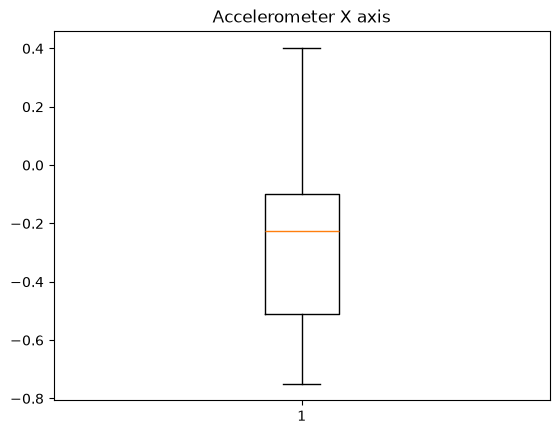

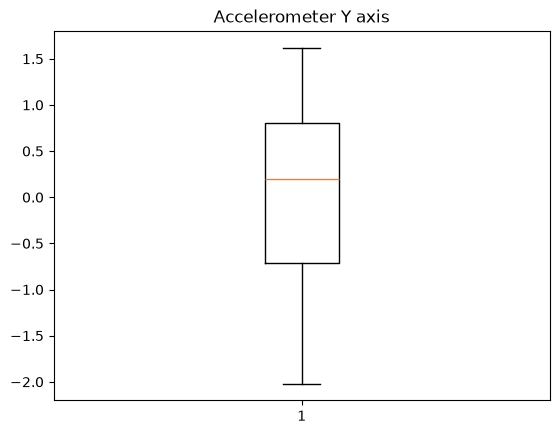

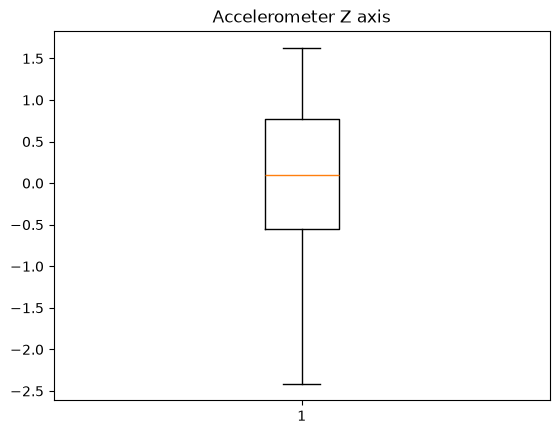

" plt.set_yticklabels(['d_1', 'd_2', 'd_3']) "

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os
from scipy import stats

path = "VitaStress/data/"
p = r"VitaStress/data/"
d_x = []
d_y = []
d_z = []

with os.scandir(p) as es:
    for e in es:
        if e.is_dir():
            with os.scandir(e) as f:
                for x in f:
                    if x.name.endswith('_acc.csv'):
                        """ with open(x.path, encoding='utf-8') as y: """
                        df = pd.read_csv(x.path)
                        accX = df["accX"]
                        accX = np.mean(accX.dropna())

                        accY = df["accY"]
                        accY = np.mean(accY.dropna())

                        accZ = df["accZ"]
                        accZ = np.mean(accZ.dropna())

                        d_x.append(accX)
                        d_y.append(accY)
                        d_z.append(accZ)

""" d = [d_x, d_y, d_z] """
plt.boxplot(stats.zscore(d_x), showfliers=False)
plt.title("Accelerometer X axis")
plt.show()
plt.boxplot(stats.zscore(d_y), showfliers=False)
plt.title("Accelerometer Y axis")
plt.show()
plt.boxplot(stats.zscore(d_z), showfliers=False)
plt.title("Accelerometer Z axis")
plt.show()

""" plt.set_yticklabels(['d_1', 'd_2', 'd_3']) """

# **Box plot per fase**  
Stessa idea di sopra, ma accX/accY/accZ vengono calcolati separatamente per ciascuna delle 4 fasi (baseline, cognitive, physical, public), usando gli intervalli temporali ricavati da `*_annotation.csv`.


accX {'baseline': 21, 'cognitive': 20, 'physical': 21, 'public': 21}
accY {'baseline': 21, 'cognitive': 20, 'physical': 21, 'public': 21}
accZ {'baseline': 21, 'cognitive': 20, 'physical': 21, 'public': 21}
stress_skin {'baseline': 21, 'cognitive': 20, 'physical': 21, 'public': 21}
bpm {'baseline': 21, 'cognitive': 20, 'physical': 21, 'public': 21}
skin_temp {'baseline': 21, 'cognitive': 20, 'physical': 21, 'public': 21}
temp_sk1 {'baseline': 21, 'cognitive': 20, 'physical': 21, 'public': 21}


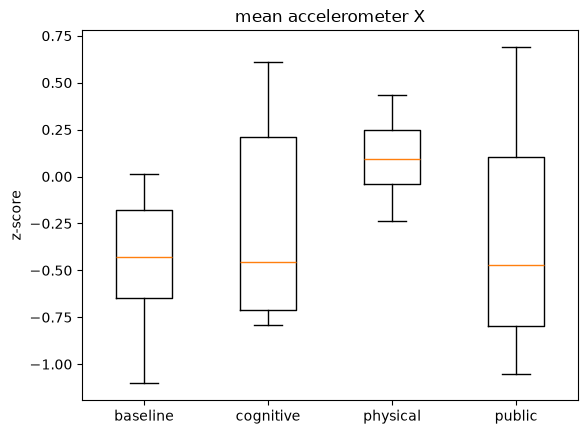

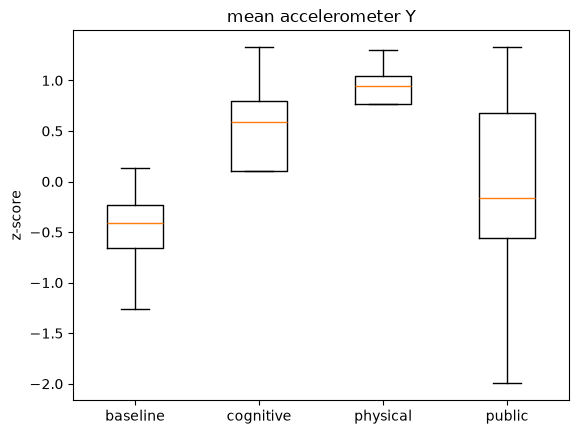

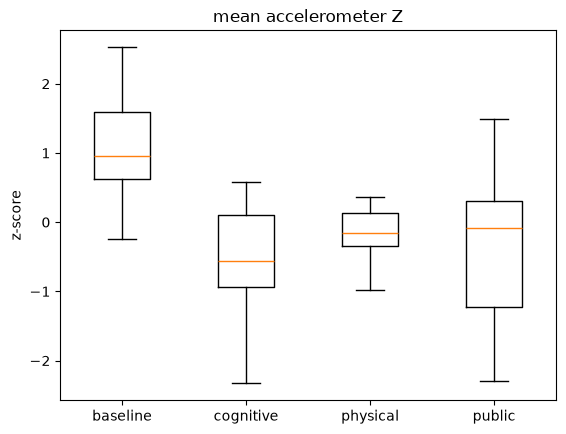

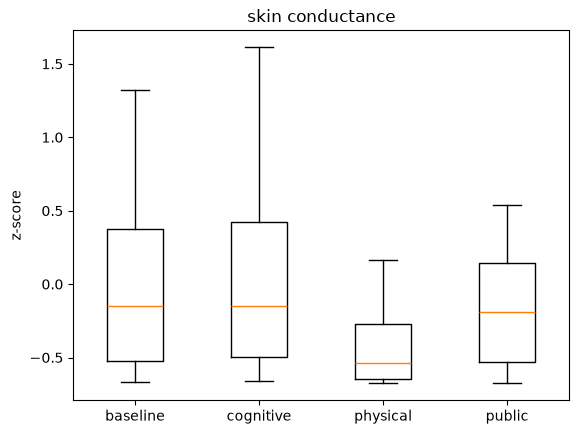

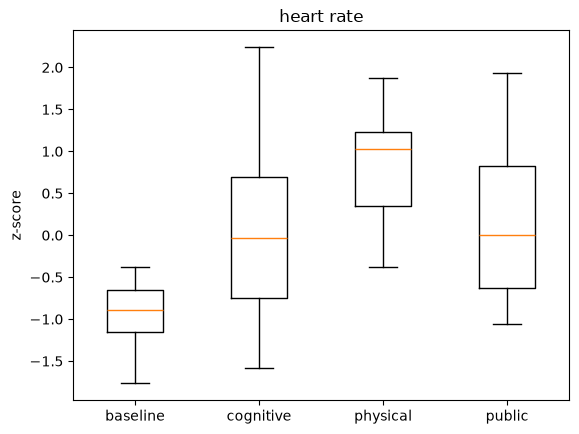

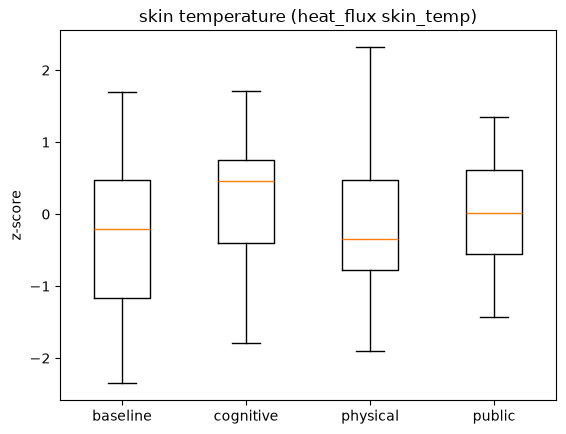

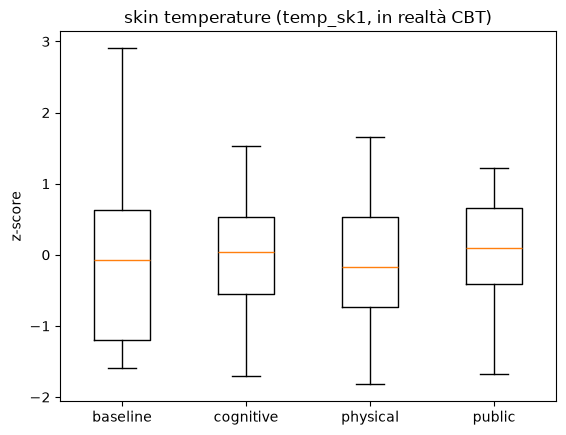

In [15]:
from scipy import stats

# file sorgente (suffisso) -> colonne da estrarre da quel file
SOURCES = {
    "_acc.csv": ["accX", "accY", "accZ"],
    "_emography.csv": ["stress_skin"],  # EDA / skin conductance
    "_activity.csv": ["bpm"],
    "_heat_flux_sensor_temperature.csv": ["skin_temp"],
    "_temperature.csv": ["temp_sk1"],  # temp_sk2 è sempre 0, temp_amb sempre vuota
}

# colonna -> titolo del grafico (come in Figura 4)
TITLES = {
    "accX": "mean accelerometer X",
    "accY": "mean accelerometer Y",
    "accZ": "mean accelerometer Z",
    "stress_skin": "skin conductance",
    "bpm": "heart rate",
    "skin_temp": "skin temperature (heat_flux skin_temp)",
    "temp_sk1": "skin temperature (temp_sk1, in realtà CBT)",
}


def phase_means(csv_path, intervals, columns):
    """Media di ciascuna colonna in ciascuna fase, per un soggetto.
    None dove la fase manca o non ha campioni nell'intervallo."""
    df = read_signal(csv_path, columns)

    means = {phase: {col: None for col in columns} for phase in PHASES}
    for phase in PHASES:
        interval = intervals[phase]
        if interval is None:
            continue

        start, stop = interval
        window = df.loc[(df.index >= start) & (df.index <= stop)]
        for col in columns:
            values = window[col].dropna()
            if not values.empty:
                means[phase][col] = values.mean()

    return means


def plot_phase_boxplot(values_by_phase, title):
    # z-score sul pool delle 4 fasi insieme (non fase per fase), poi riseparato
    # per il plot: coerente con "z-scored variables ... collected under four
    # experimental conditions" (paper, sez. 4.1.2)
    pooled = np.concatenate([values_by_phase[phase] for phase in PHASES])
    pooled_z = stats.zscore(pooled)

    z_by_phase = []
    idx = 0
    for phase in PHASES:
        n = len(values_by_phase[phase])
        z_by_phase.append(pooled_z[idx: idx + n])
        idx += n

    plt.figure()
    plt.boxplot(z_by_phase, tick_labels=PHASES, showfliers=False)
    plt.title(title)
    plt.ylabel("z-score")
    plt.show()


# d["accX"]["baseline"] = lista delle medie di accX in baseline, una per soggetto
d = {col: {phase: [] for phase in PHASES} for columns in SOURCES.values() for col in columns}
skipped = []

with os.scandir(DATA_DIR) as subjects:
    for subject_dir in subjects:
        if not subject_dir.is_dir():
            continue

        paths = subject_files(subject_dir)

        if "_annotation.csv" not in paths:
            skipped.append((subject_dir.name, "file _annotation.csv mancante"))
            continue

        intervals = get_phase_intervals(paths["_annotation.csv"])

        for suffix, columns in SOURCES.items():
            if suffix not in paths:
                skipped.append((subject_dir.name, f"file {suffix} mancante"))
                continue

            means = phase_means(paths[suffix], intervals, columns)
            for phase in PHASES:
                for col in columns:
                    value = means[phase][col]
                    if value is None:
                        skipped.append((subject_dir.name, f"{phase}/{col}"))
                    else:
                        d[col][phase].append(value)
print()
for col in d:
    print(col, {phase: len(d[col][phase]) for phase in PHASES})

for col, title in TITLES.items():
    plot_phase_boxplot(d[col], title)

# **Riproduzione Figura 5 del preprint (finestre da 30 s)**  
Segue lo schema della pipeline del preprint (Figura 3, sez. 3.6): accelerometro aggregato (mean/std/var) e segnali vitali ricampionati su finestre da 30 s, etichette dalle annotation, z-score **per soggetto** calcolato sulle righe delle 4 fasi. Zeri di `bpm`/`temp_sk1` trattati come mancanti. Violin plot con box interno e media (rombo giallo) come nel paper.

Scartati:
  - id_7bb4dafd-5a92-4aef-91e1-d634b40bc353: fase cognitive senza Start/Stop
finestre per fase: {'baseline': 436, 'cognitive': 186, 'physical': 331, 'public': 194}

% mancanti per fase:
           accX_mean  accY_mean  accZ_mean  stress_skin  bpm  temp_sk1
phase                                                                 
baseline         1.1        1.1        1.1          1.4  1.1       1.1
cognitive        0.0        0.0        0.0          0.0  3.2       0.5
physical         0.0        0.0        0.0          0.0  2.4       0.3
public           0.0        0.0        0.0          0.0  3.6       0.0


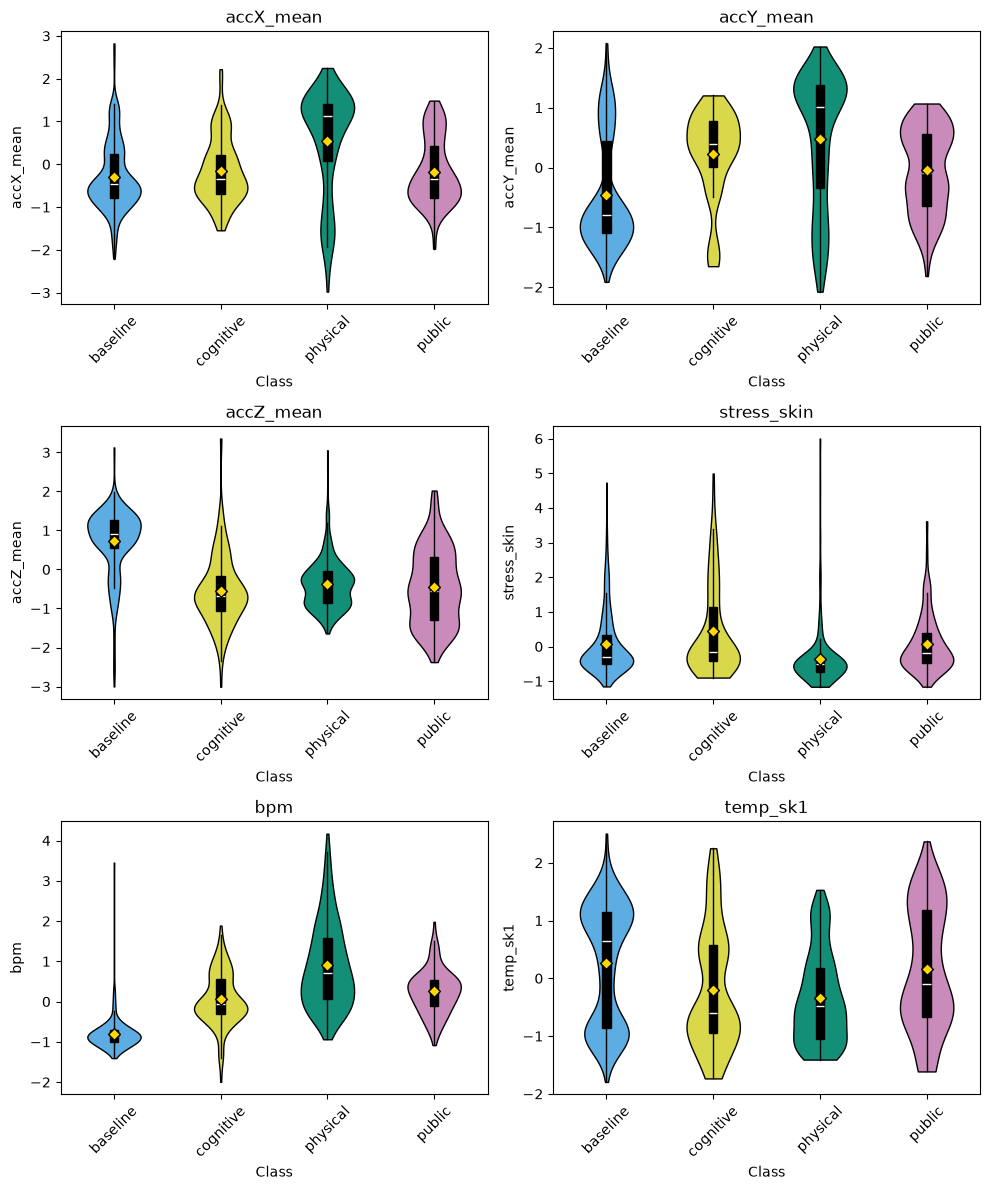

In [16]:
# le 6 feature della Figura 5 del preprint, con gli stessi nomi
FIG5_FEATURES = ["accX_mean", "accY_mean", "accZ_mean", "stress_skin", "bpm", "temp_sk1"]
PHASE_COLORS = {"baseline": "#5DADE2", "cognitive": "#D9D84A", "physical": "#148F77", "public": "#C98BB9"}


def plot_fig5(table):
    fig, axs = plt.subplots(3, 2, figsize=(10, 12))
    positions = range(1, len(PHASES) + 1)
    for ax, col in zip(axs.ravel(), FIG5_FEATURES):
        by_phase = [table.loc[table["phase"] == phase, col].dropna() for phase in PHASES]

        bodies = ax.violinplot(by_phase, positions, showextrema=False)["bodies"]
        for body, phase in zip(bodies, PHASES):
            body.set_facecolor(PHASE_COLORS[phase])
            body.set_edgecolor("black")
            body.set_alpha(1)
        ax.boxplot(by_phase, positions=positions, widths=0.08, showfliers=False, showcaps=False,
                   patch_artist=True, boxprops={"facecolor": "black"}, medianprops={"color": "white"})
        ax.scatter(positions, [v.mean() for v in by_phase], marker="D", color="gold",
                   edgecolor="black", zorder=3)  # media, il "yellow diamond" della didascalia

        ax.set_xticks(positions, PHASES, rotation=45)
        ax.set_title(col)
        ax.set_ylabel(col)
        ax.set_xlabel("Class")
    fig.tight_layout()
    plt.show()


table, skipped = build_window_table()
feature_columns = [col for col in table.columns if col not in ("phase", "subject")]
table_z = zscore_per_subject(table, feature_columns)

if skipped:
    print("Scartati:")
    for name, reason in skipped:
        print(f"  - {name}: {reason}")
print("finestre per fase:", table.groupby("phase").size().to_dict())
# confronto con la Figura 4 del preprint (% mancanti per classe)
print("\n% mancanti per fase:")
print((table.groupby("phase")[FIG5_FEATURES].apply(lambda g: g.isna().mean()) * 100).round(1))

plot_fig5(table_z)